In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load processed dataset
df = pd.read_csv("../data/news.csv")

print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Shape: (44898, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  int64
dtypes: int64(1), str(4)
memory usage: 1.7 MB
None

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


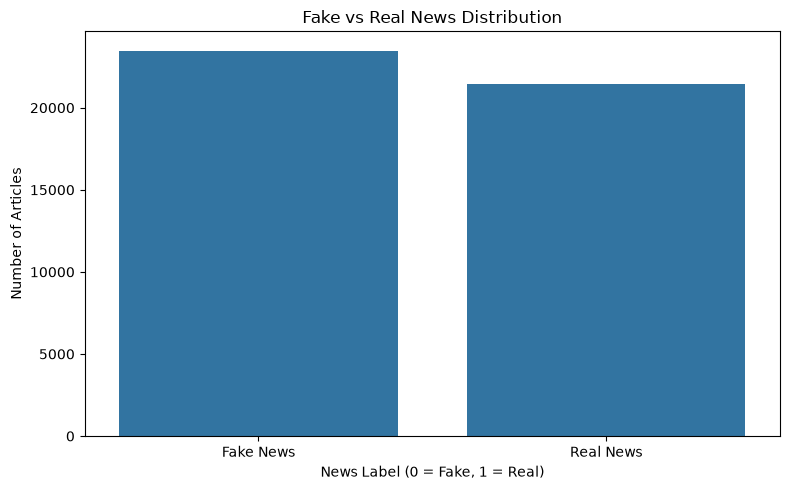

In [2]:
# Visualize Fake vs Real News Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake News", "Real News"])

plt.tight_layout()
plt.show()

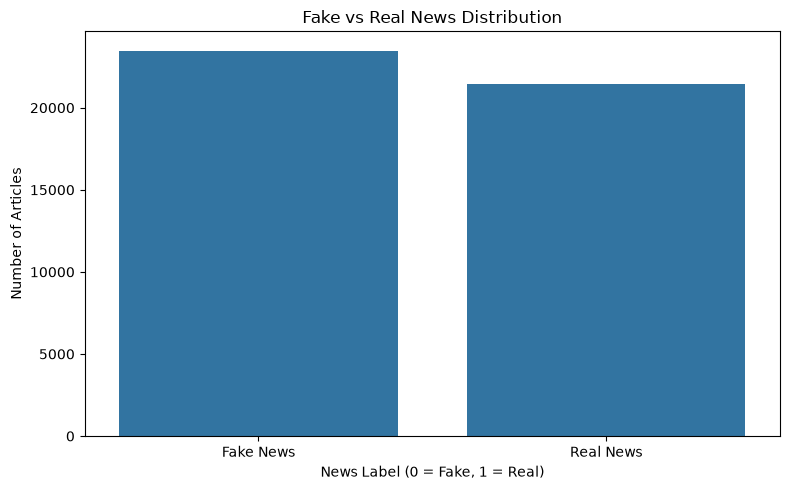

In [3]:
# Visualize Fake vs Real News Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Fake vs Real News Distribution")
plt.xlabel("News Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake News", "Real News"])

plt.tight_layout()
plt.show()

News Articles by Subject:

subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


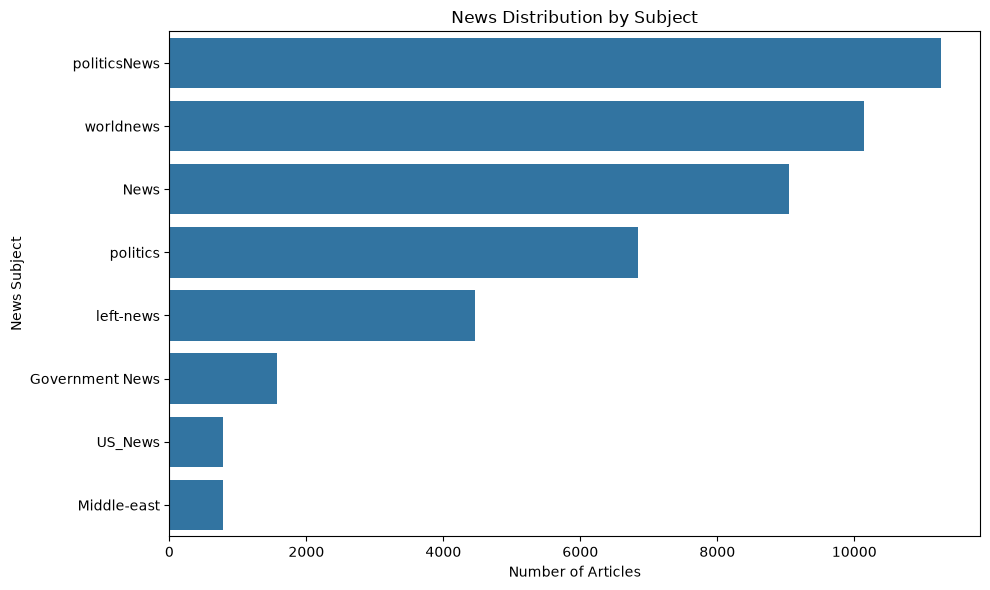

In [4]:
# Subject-wise News Distribution

print("News Articles by Subject:\n")
print(df["subject"].value_counts())

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="subject",
    order=df["subject"].value_counts().index
)

plt.title("News Distribution by Subject")
plt.xlabel("Number of Articles")
plt.ylabel("News Subject")

plt.tight_layout()
plt.show()

Top Fake News Words:
          Word  Frequency
913      trump      79300
769       said      33763
672  president      27715
636     people      26570
467       just      20511
175    clinton      19173
607      obama      18797
508       like      18097
271     donald      17671
595       news      14620
594        new      14394
402    hillary      14122
903       time      13844
848      state      13463
970      white      13189

Top Real News Words:
           Word  Frequency
804        said      99062
935       trump      54700
783     reuters      28976
686   president      28177
871       state      21025
383  government      18846
601         new      16917
874      states      16652
416       house      16640
771  republican      16243
945      united      15590
656      people      15287
995        year      14777
922        told      14245
972  washington      12988


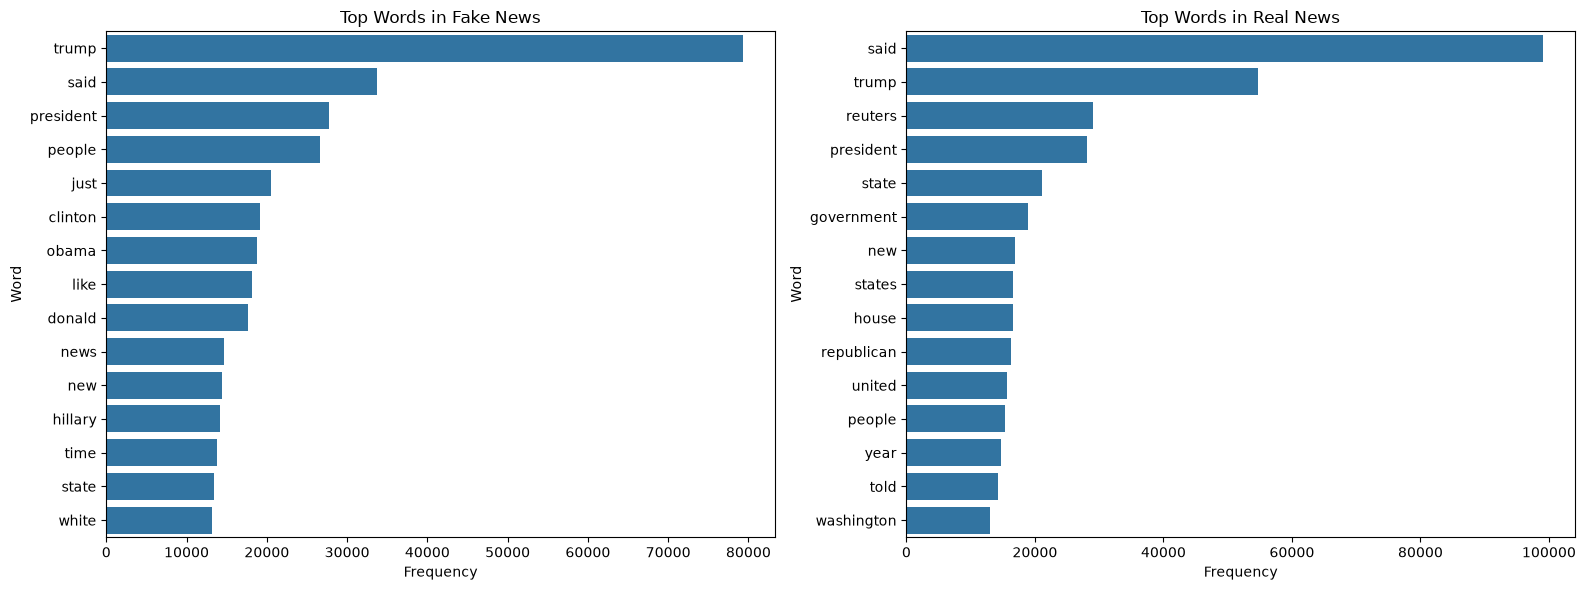

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Separate Fake and Real news
fake_news = df[df["label"] == 0]["text"]
real_news = df[df["label"] == 1]["text"]

# Function to find most common words
def get_top_words(text_data, n=15):

    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=1000
    )

    matrix = vectorizer.fit_transform(text_data)

    word_counts = matrix.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        "Word": words,
        "Frequency": word_counts
    })

    return result.sort_values(
        by="Frequency",
        ascending=False
    ).head(n)


# Get top words
fake_top_words = get_top_words(fake_news)
real_top_words = get_top_words(real_news)

print("Top Fake News Words:")
print(fake_top_words)

print("\nTop Real News Words:")
print(real_top_words)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=fake_top_words,
    x="Frequency",
    y="Word",
    ax=axes[0]
)

axes[0].set_title("Top Words in Fake News")

sns.barplot(
    data=real_top_words,
    x="Frequency",
    y="Word",
    ax=axes[1]
)

axes[1].set_title("Top Words in Real News")

plt.tight_layout()
plt.show()

Correlation Matrix:
                 label  title_length  text_length
label         1.000000     -0.580489    -0.053405
title_length -0.580489      1.000000     0.046501
text_length  -0.053405      0.046501     1.000000


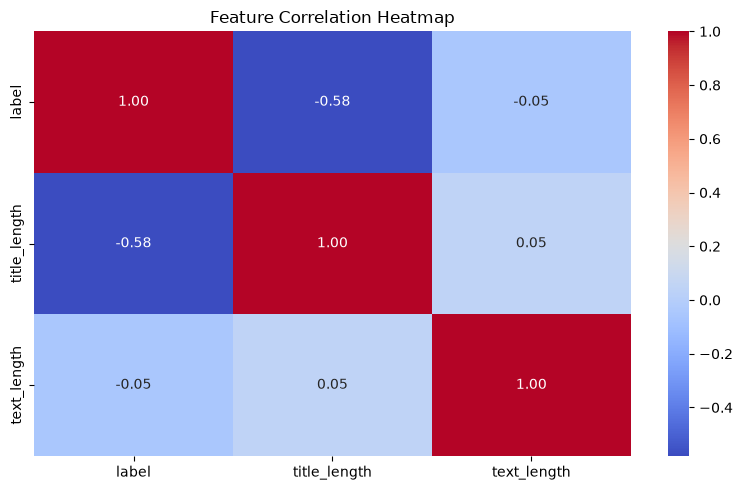

In [6]:
# Numerical Feature Analysis

df["title_length"] = df["title"].fillna("").apply(
    lambda x: len(str(x).split())
)

df["text_length"] = df["text"].fillna("").apply(
    lambda x: len(str(x).split())
)

correlation_data = df[
    ["label", "title_length", "text_length"]
]

print("Correlation Matrix:")
print(correlation_data.corr())

# Heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
# Duplicate News Analysis

print("Total Articles:", len(df))

print("\nDuplicate Titles:")
print(df["title"].duplicated().sum())

print("\nDuplicate News Texts:")
print(df["text"].duplicated().sum())

print("\nDuplicate Complete Articles:")
print(
    (df["title"].fillna("") + df["text"].fillna(""))
    .duplicated()
    .sum()
)

Total Articles: 44898

Duplicate Titles:
6169

Duplicate News Texts:
6252

Duplicate Complete Articles:
5793


In [8]:
# Final Dataset Summary

print("DATASET SUMMARY")
print("-" * 40)

print("Total Articles:", len(df))
print("Fake News:", (df["label"] == 0).sum())
print("Real News:", (df["label"] == 1).sum())

print("\nUnique Subjects:")
print(df["subject"].nunique())

print("\nAvailable Subjects:")
print(df["subject"].unique())

print("\nDataset Columns:")
print(df.columns.tolist())

DATASET SUMMARY
----------------------------------------
Total Articles: 44898
Fake News: 23481
Real News: 21417

Unique Subjects:
8

Available Subjects:
<StringArray>
[        'US_News',    'politicsNews',            'News', 'Government News',
       'left-news',       'worldnews',        'politics',     'Middle-east']
Length: 8, dtype: str

Dataset Columns:
['title', 'text', 'subject', 'date', 'label', 'title_length', 'text_length']


In [9]:
# Data Leakage Check

from sklearn.model_selection import train_test_split

df["content"] = (
    df["title"].fillna("") + " " + df["text"].fillna("")
).str.lower().str.strip()

X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_articles = set(X_train)

leakage_count = X_test.isin(train_articles).sum()

print("DATA LEAKAGE ANALYSIS")
print("-" * 40)
print("Training Articles:", len(X_train))
print("Testing Articles:", len(X_test))
print("Overlapping Test Articles:", leakage_count)
print(
    "Leakage Percentage:",
    round((leakage_count / len(X_test)) * 100, 2), "%"
)

DATA LEAKAGE ANALYSIS
----------------------------------------
Training Articles: 35918
Testing Articles: 8980
Overlapping Test Articles: 1816
Leakage Percentage: 20.22 %


In [10]:
# Remove Exact Duplicate Articles

print("Before Removing Duplicates:", len(df))

df_clean = df.drop_duplicates(
    subset=["title", "text"]
).copy()

df_clean = df_clean.reset_index(drop=True)

print("After Removing Duplicates:", len(df_clean))
print("Removed Articles:", len(df) - len(df_clean))

print("\nLabel Distribution After Cleaning:")
print(df_clean["label"].value_counts())


Before Removing Duplicates: 44898
After Removing Duplicates: 39105
Removed Articles: 5793

Label Distribution After Cleaning:
label
1    21197
0    17908
Name: count, dtype: int64


In [11]:
# Save Cleaned Dataset

df_clean.to_csv("../data/news_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("File: data/news_cleaned.csv")
print("Total Articles:", len(df_clean))

Cleaned dataset saved successfully!
File: data/news_cleaned.csv
Total Articles: 39105
